# Credit Card Fraud Detection: Analysis, Modeling and Business Impact

**Goal:** catch as much fraud (by count *and* by value) as possible while keeping the number of false alarms an analyst team has to review manageable.

**Data:** 284,807 card transactions from two days (European cardholders). `V1`-`V28` are anonymized PCA components, `Time` is seconds since the first transaction, `Amount` is the transaction value and `Class` is 1 for fraud. Only 0.17% of transactions are fraud.

**Notebook outline**
1. Setup and data cleaning
2. SQL analysis (fraud by amount band and by hour)
3. Exploratory data analysis
4. Train/test split and preprocessing
5. Model comparison with cross-validation (training data only): 9 models, ROC/PR curves, confusion matrices
6. Threshold selection
7. One-time evaluation on the held-out test set, robustness check, feature importance and SHAP
8. Business impact
9. Conclusions and limitations

> Place `creditcard.csv` in the same folder as this notebook (in Colab, upload it first).

## 1. Setup and data cleaning

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline as sk_make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
import xgboost as xgb
import shap

RANDOM_STATE = 42
DATA_PATH = "creditcard.csv"
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
raw = pd.read_csv(DATA_PATH)

print("Shape:", raw.shape)
print("Missing values:", raw.isnull().sum().sum())
n_dup = raw.duplicated().sum()
print(f"Duplicate rows: {n_dup:,} (of which fraud: {raw[raw.duplicated()]['Class'].sum()})")

# Exact duplicates can land in both train and test and inflate scores, so drop them.
df = raw.drop_duplicates().reset_index(drop=True)

print(f"\nAfter dropping duplicates: {df.shape[0]:,} rows")
print(f"Fraud cases: {df['Class'].sum():,}  ({df['Class'].mean()*100:.3f}%)")
print(f"Imbalance ratio: {(df['Class']==0).sum() / (df['Class']==1).sum():.0f} normal per 1 fraud")

Shape: (284807, 31)
Missing values: 0


Duplicate rows: 1,081 (of which fraud: 19)



After dropping duplicates: 283,726 rows
Fraud cases: 473  (0.167%)
Imbalance ratio: 599 normal per 1 fraud


## 2. SQL analysis

The same table is loaded into SQLite so that the business questions can be answered in SQL: how does fraud vary with **transaction size** and with **time**?

In [3]:
conn = sqlite3.connect(":memory:")
df.to_sql("transactions", conn, index=False)

def sql(query):
    return pd.read_sql(query, conn)

# 1) Overall fraud vs normal
sql('''
SELECT Class,
       COUNT(*)                  AS transactions,
       ROUND(AVG(Amount), 2)     AS avg_amount,
       ROUND(MAX(Amount), 2)     AS max_amount,
       ROUND(SUM(Amount), 0)     AS total_amount
FROM transactions
GROUP BY Class
''')

,Class,transactions,avg_amount,max_amount,total_amount
0,0,283253,88.4100,"25,691.1600","25,043,410.0000"
1,1,473,123.8700,"2,125.8700","58,591.0000"


In [4]:
# 1b) The 10 largest fraudulent transactions
sql('''
SELECT Time, Amount, Class
FROM transactions
WHERE Class = 1
ORDER BY Amount DESC
LIMIT 10
''')

,Time,Amount,Class
0,"122,608.0000","2,125.8700",1
1,"9,064.0000","1,809.6800",1
2,"154,278.0000","1,504.9300",1
3,"62,467.0000","1,402.1600",1
4,"59,011.0000","1,389.5600",1
5,"65,385.0000","1,354.2500",1
6,"133,184.0000","1,335.0000",1
7,"18,088.0000","1,218.8900",1
8,"154,309.0000","1,096.9900",1
9,"147,501.0000",996.2700,1


,amount_band,transactions,frauds,fraud_rate_pct,pct_of_all_fraud
0,1) under 1,16765,66,0.3940,14.0000
1,2) 1 - 10,80108,172,0.2150,36.4000
2,3) 10 - 50,91937,54,0.0590,11.4000
3,4) 50 - 200,65668,99,0.1510,20.9000
4,"5) 200 - 1,000",26184,73,0.2790,15.4000
5,"6) 1,000+",3064,9,0.2940,1.9000


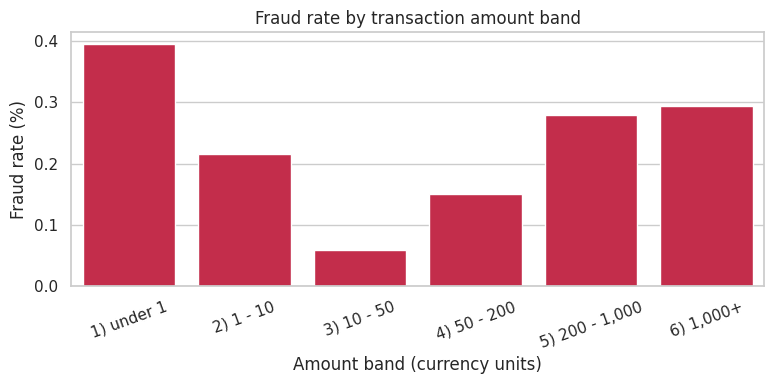

In [5]:
# 2) Fraud by amount band. SUM(...) OVER () gives each band's share of all fraud.
bands = sql('''
SELECT CASE WHEN Amount < 1    THEN '1) under 1'
            WHEN Amount < 10   THEN '2) 1 - 10'
            WHEN Amount < 50   THEN '3) 10 - 50'
            WHEN Amount < 200  THEN '4) 50 - 200'
            WHEN Amount < 1000 THEN '5) 200 - 1,000'
            ELSE                    '6) 1,000+' END AS amount_band,
       COUNT(*)                                        AS transactions,
       SUM(Class)                                      AS frauds,
       ROUND(100.0 * SUM(Class) / COUNT(*), 3)         AS fraud_rate_pct,
       ROUND(100.0 * SUM(Class) / SUM(SUM(Class)) OVER (), 1) AS pct_of_all_fraud
FROM transactions
GROUP BY amount_band
ORDER BY amount_band
''')
display(bands)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=bands, x="amount_band", y="fraud_rate_pct", color="crimson", ax=ax)
ax.set_title("Fraud rate by transaction amount band")
ax.set_xlabel("Amount band (currency units)")
ax.set_ylabel("Fraud rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

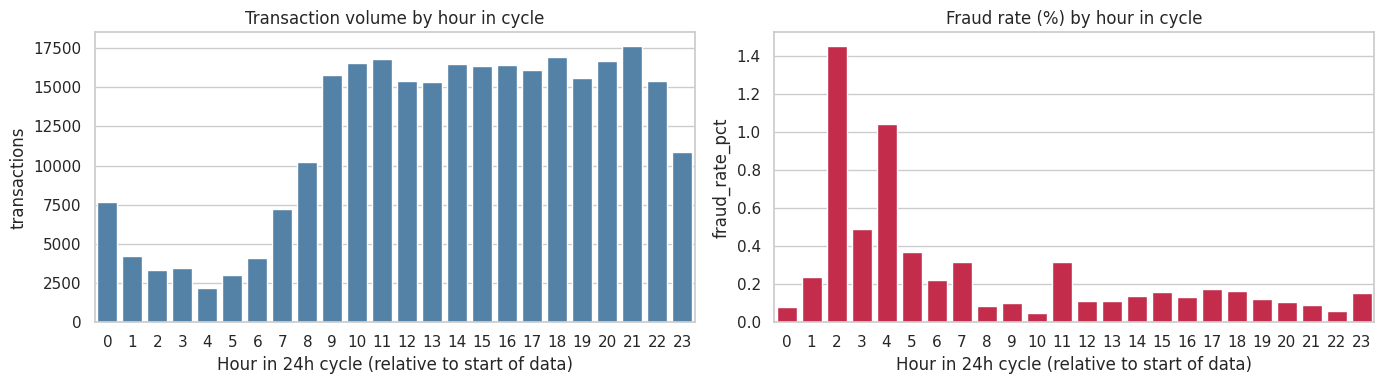

,hour_in_cycle,transactions,frauds,fraud_rate_pct,fraud_rate_rank
2,2,3308,48,1.4510,1
4,4,2204,23,1.0440,2
3,3,3487,17,0.4880,3
5,5,2988,11,0.3680,4
7,7,7233,23,0.3180,5


In [6]:
# 3) Fraud by hour. Time is seconds since the FIRST transaction, so this is "hour of the
#    24h cycle relative to the start of the data", not the real clock hour.
hourly = sql('''
WITH hourly AS (
    SELECT CAST(Time / 3600 AS INTEGER) % 24 AS hour_in_cycle,
           COUNT(*)  AS transactions,
           SUM(Class) AS frauds
    FROM transactions
    GROUP BY 1
)
SELECT hour_in_cycle,
       transactions,
       frauds,
       ROUND(100.0 * frauds / transactions, 3) AS fraud_rate_pct,
       RANK() OVER (ORDER BY 1.0 * frauds / transactions DESC) AS fraud_rate_rank
FROM hourly
ORDER BY hour_in_cycle
''')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=hourly, x="hour_in_cycle", y="transactions", color="steelblue", ax=axes[0])
axes[0].set_title("Transaction volume by hour in cycle")
axes[0].set_xlabel("Hour in 24h cycle (relative to start of data)")
sns.barplot(data=hourly, x="hour_in_cycle", y="fraud_rate_pct", color="crimson", ax=axes[1])
axes[1].set_title("Fraud rate (%) by hour in cycle")
axes[1].set_xlabel("Hour in 24h cycle (relative to start of data)")
plt.tight_layout()
plt.show()

display(hourly.sort_values("fraud_rate_pct", ascending=False).head(5))

## 3. Exploratory data analysis

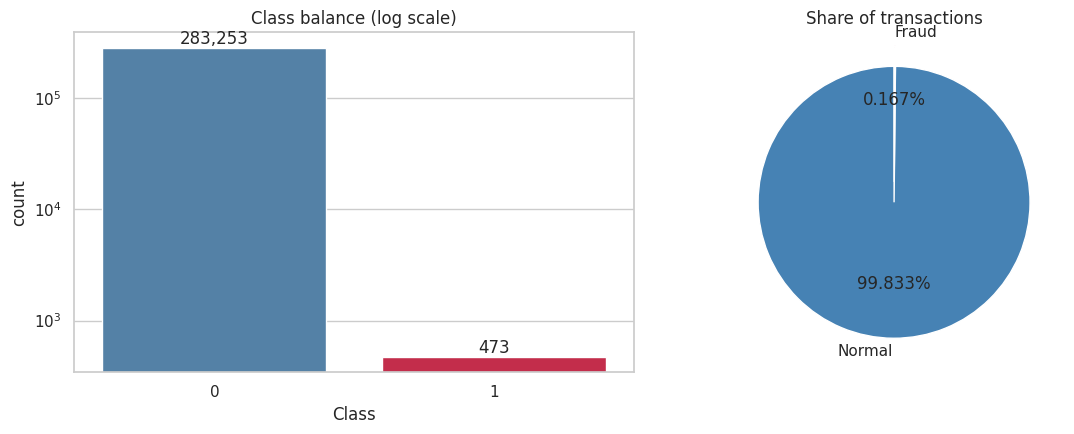

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Class balance (log scale, otherwise the fraud bar is invisible)
sns.countplot(data=df, x="Class", hue="Class", palette=["steelblue", "crimson"], legend=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Class balance (log scale)")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

# Share of transactions (pie)
counts = df["Class"].value_counts().sort_index()
axes[1].pie(counts.values, labels=["Normal", "Fraud"], autopct="%1.3f%%", startangle=90,
            colors=["steelblue", "crimson"], explode=(0, 0.15))
axes[1].set_title("Share of transactions")
plt.tight_layout()
plt.show()

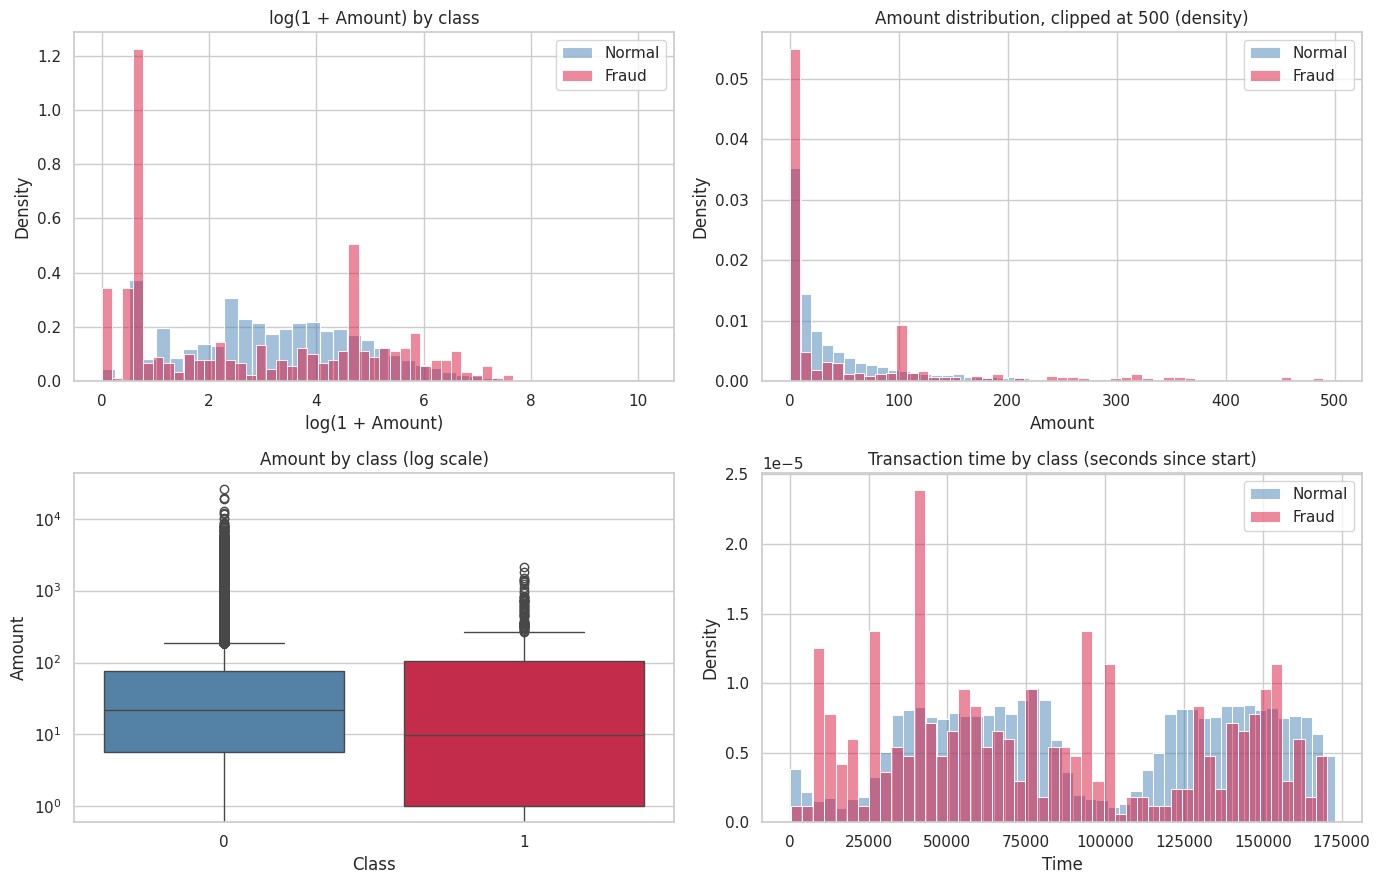

             count     mean      std    min    25%     50%      75%  \
Class                                                                 
0     283,253.0000  88.4100 250.3800 0.0000 5.6700 22.0000  77.4600   
1         473.0000 123.8700 260.2100 0.0000 1.0000  9.8200 105.8900   

              max  
Class              
0     25,691.1600  
1      2,125.8700  

             count        mean         std      min         25%         50%  \
Class                                                                         
0     283,253.0000 94,835.0000 47,476.0000   0.0000 54,233.0000 84,711.0000   
1         473.0000 80,451.0000 48,636.0000 406.0000 41,203.0000 73,408.0000   

               75%          max  
Class                            
0     139,308.0000 172,792.0000  
1     129,095.0000 170,348.0000  


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Amount distribution by class (density, so the classes are comparable)
for cls, color, label in [(0, "steelblue", "Normal"), (1, "crimson", "Fraud")]:
    sns.histplot(np.log1p(df.loc[df["Class"] == cls, "Amount"]), bins=40, stat="density",
                 color=color, alpha=0.5, label=label, ax=axes[0, 0])
axes[0, 0].set_title("log(1 + Amount) by class")
axes[0, 0].set_xlabel("log(1 + Amount)")
axes[0, 0].legend()

# Amount histograms clipped to 0-500 (where most transactions are)
for cls, color, label in [(0, "steelblue", "Normal"), (1, "crimson", "Fraud")]:
    sns.histplot(df.loc[(df["Class"] == cls) & (df["Amount"] <= 500), "Amount"], bins=50,
                 stat="density", color=color, alpha=0.5, label=label, ax=axes[0, 1])
axes[0, 1].set_title("Amount distribution, clipped at 500 (density)")
axes[0, 1].legend()

# Amount boxplot
sns.boxplot(data=df, x="Class", y="Amount", hue="Class", palette=["steelblue", "crimson"],
            legend=False, ax=axes[1, 0])
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Amount by class (log scale)")

# Time by class
for cls, color, label in [(0, "steelblue", "Normal"), (1, "crimson", "Fraud")]:
    sns.histplot(df.loc[df["Class"] == cls, "Time"], bins=48, stat="density",
                 color=color, alpha=0.5, label=label, ax=axes[1, 1])
axes[1, 1].set_title("Transaction time by class (seconds since start)")
axes[1, 1].legend()
plt.tight_layout()
plt.show()

print(df.groupby("Class")["Amount"].describe().round(2))
print()
print(df.groupby("Class")["Time"].describe().round(0))

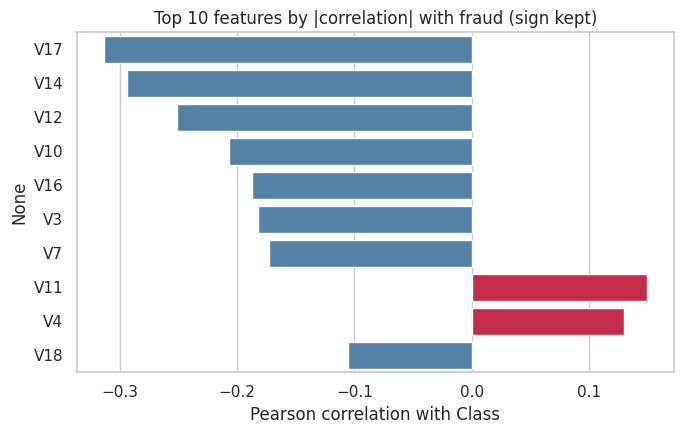

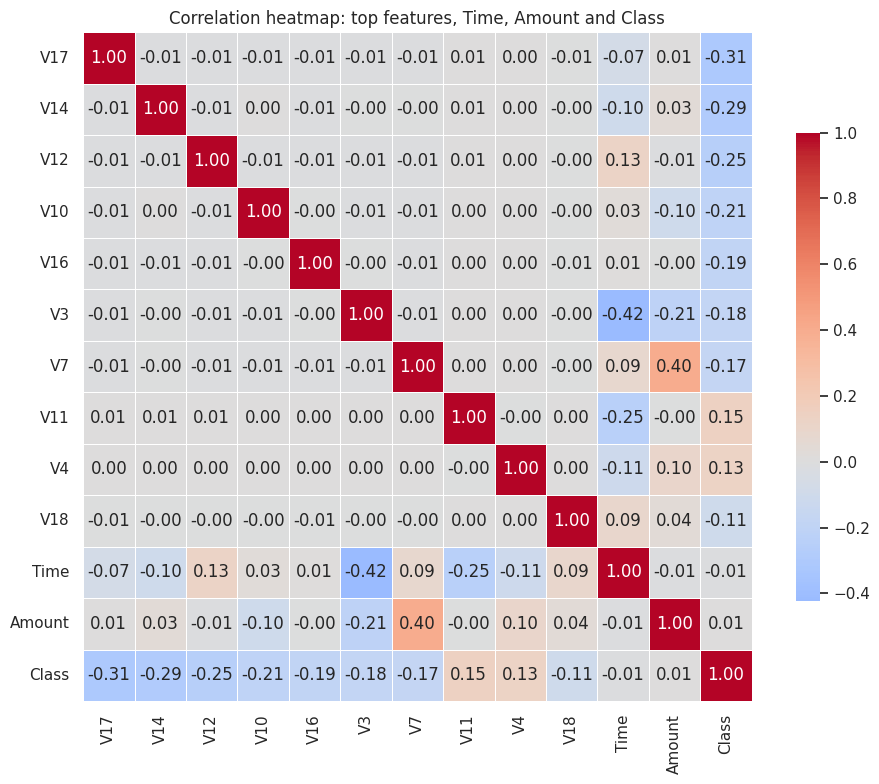

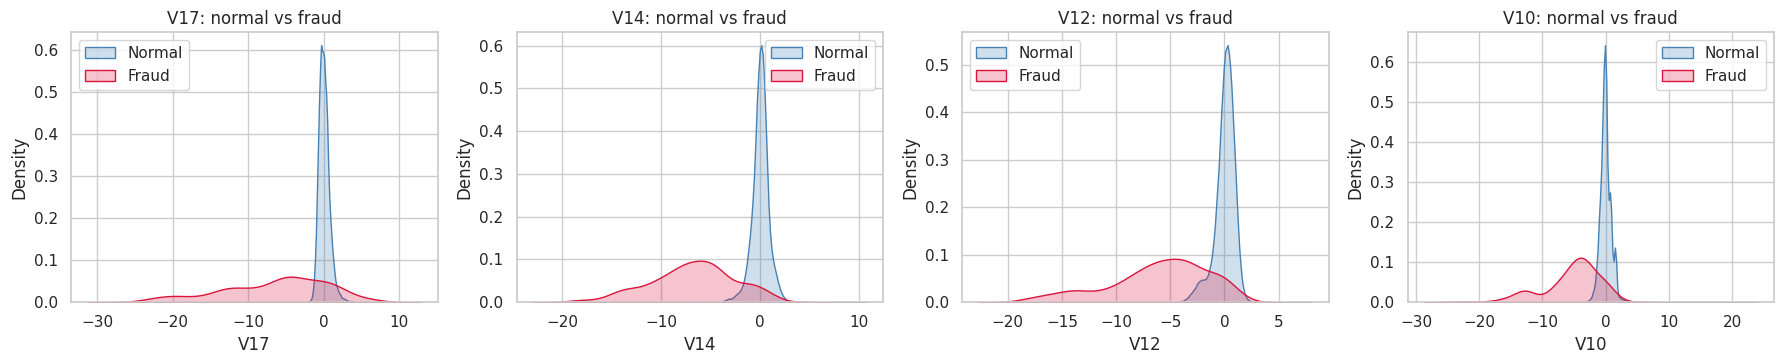

In [9]:
corr = df.corr()["Class"].drop("Class")
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(10)

plt.figure(figsize=(7, 4.5))
colors = ["crimson" if v > 0 else "steelblue" for v in top_corr.values]
sns.barplot(x=top_corr.values, y=top_corr.index, palette=colors, orient="h")
plt.title("Top 10 features by |correlation| with fraud (sign kept)")
plt.xlabel("Pearson correlation with Class")
plt.tight_layout()
plt.show()

# Correlation heatmap of the most relevant features
heat_cols = list(top_corr.index) + ["Time", "Amount", "Class"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[heat_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7})
plt.title("Correlation heatmap: top features, Time, Amount and Class")
plt.tight_layout()
plt.show()

top4 = top_corr.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, feat in zip(axes, top4):
    sns.kdeplot(df.loc[df["Class"] == 0, feat], fill=True, color="steelblue", label="Normal", ax=ax)
    sns.kdeplot(df.loc[df["Class"] == 1, feat], fill=True, color="crimson", label="Fraud", ax=ax)
    ax.set_title(f"{feat}: normal vs fraud")
    ax.legend()
plt.tight_layout()
plt.show()

Pearson correlation is only a first look (the target is binary and extremely imbalanced). The models below capture non-linear patterns, so feature importance is checked again after training.

## 4. Train/test split and preprocessing

The data is split **once**, stratified so both parts keep the 0.17% fraud rate. The test set is not used for any modeling decision. Scaling and resampling happen **inside** a pipeline, so they are fitted on training data only (no leakage).

`V1`-`V28` are already PCA-scaled. `Time` is standardized and `Amount` is log-transformed (it is heavily skewed) and then standardized.

In [10]:
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} rows, {y_train.sum()} fraud ({y_train.mean()*100:.3f}%)")
print(f"Test : {len(X_test):,} rows, {y_test.sum()} fraud ({y_test.mean()*100:.3f}%)")

FEATURES = ["Time", "Amount"] + [c for c in X.columns if c not in ("Time", "Amount")]

def make_prep():
    return ColumnTransformer(
        [("time", StandardScaler(), ["Time"]),
         ("amount", sk_make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), ["Amount"])],
        remainder="passthrough")   # output order: Time, Amount, then V1..V28

Train: 226,980 rows, 378 fraud (0.167%)
Test : 56,746 rows, 95 fraud (0.167%)


## 5. Model comparison with cross-validation (training data only)

Nine candidates are compared with 5-fold stratified cross-validation on the **training set**. SMOTE is applied only to each fold's training portion, never to its validation portion.

The main metric is **AUC-PR** (average precision). With 0.17% fraud, accuracy and AUC-ROC look great even for weak models, while AUC-PR reflects how well fraud is ranked above normal traffic. The mean and standard deviation across folds show how much of a gap is real versus noise.

In [11]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

def make_xgb(**kw):
    return xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8,
                             colsample_bytree=0.8, tree_method="hist", eval_metric="aucpr",
                             random_state=RANDOM_STATE, n_jobs=-1, **kw)

candidates = {
    "Logistic Regression": Pipeline([
        ("prep", make_prep()), ("model", LogisticRegression(max_iter=2000))]),
    "Logistic Regression + SMOTE": Pipeline([
        ("prep", make_prep()), ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=2000))]),
    "Random Forest (class-weighted)": Pipeline([
        ("prep", make_prep()),
        ("model", RandomForestClassifier(n_estimators=100, max_depth=10, max_samples=0.25,
                                         class_weight="balanced_subsample", n_jobs=-1,
                                         random_state=RANDOM_STATE))]),
    "XGBoost (unweighted)": Pipeline([("prep", make_prep()), ("model", make_xgb())]),
    "XGBoost (class-weighted)": Pipeline([
        ("prep", make_prep()), ("model", make_xgb(scale_pos_weight=pos_weight))]),
    "XGBoost + SMOTE": Pipeline([
        ("prep", make_prep()), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", make_xgb())]),
    "Logistic Regression + Undersampling": Pipeline([
        ("prep", make_prep()), ("under", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=2000))]),
    "Random Forest + SMOTE": Pipeline([
        ("prep", make_prep()), ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", RandomForestClassifier(n_estimators=100, max_depth=10, max_samples=0.25,
                                         n_jobs=-1, random_state=RANDOM_STATE))]),
    "Neural Network + SMOTE": Pipeline([
        ("prep", make_prep()), ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=60, early_stopping=True,
                                validation_fraction=0.1, random_state=RANDOM_STATE))]),
}

def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    i = int(np.argmax(f1))
    return t[i], f1[i], p[i], r[i]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba, rows = {}, []

for name, pipe in candidates.items():
    oof = np.zeros(len(y_train))
    fold_ap = []
    for tr, va in cv.split(X_train, y_train):
        model = clone(pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        proba = model.predict_proba(X_train.iloc[va])[:, 1]
        oof[va] = proba
        fold_ap.append(average_precision_score(y_train.iloc[va], proba))
    oof_proba[name] = oof
    pred05 = (oof >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "AUC-PR (mean)": np.mean(fold_ap),
        "AUC-PR (std)": np.std(fold_ap),
        "AUC-ROC": roc_auc_score(y_train, oof),
        "Precision @0.5": precision_score(y_train, pred05, zero_division=0),
        "Recall @0.5": recall_score(y_train, pred05),
        "Best F1 (any threshold)": best_f1_threshold(y_train, oof)[1],
    })
    print(f"done: {name}")

cv_results = pd.DataFrame(rows).sort_values("AUC-PR (mean)", ascending=False).reset_index(drop=True)
cv_results

done: Logistic Regression


done: Logistic Regression + SMOTE


done: Random Forest (class-weighted)


done: XGBoost (unweighted)


done: XGBoost (class-weighted)


done: XGBoost + SMOTE


done: Logistic Regression + Undersampling


done: Random Forest + SMOTE


done: Neural Network + SMOTE


,Model,AUC-PR (mean),AUC-PR (std),AUC-ROC,Precision @0.5,Recall @0.5,Best F1 (any threshold)
0,XGBoost (unweighted),0.8501,0.0285,0.9809,0.9344,0.7910,0.8731
1,XGBoost (class-weighted),0.8443,0.0267,0.9783,0.8764,0.8254,0.8636
2,XGBoost + SMOTE,0.8369,0.0291,0.9779,0.5727,0.8333,0.8645
3,Random Forest (class-weighted),0.8137,0.0370,0.9618,0.8719,0.7381,0.8360
4,Neural Network + SMOTE,0.8119,0.0507,0.9632,0.7722,0.8069,0.8278
5,Random Forest + SMOTE,0.8051,0.0299,0.9813,0.5922,0.8413,0.8222
6,Logistic Regression,0.7551,0.0310,0.9774,0.8657,0.6138,0.7819
7,Logistic Regression + SMOTE,0.7393,0.0248,0.9791,0.0549,0.9048,0.8123
8,Logistic Regression + Undersampling,0.6031,0.1182,0.9799,0.0424,0.9127,0.6306


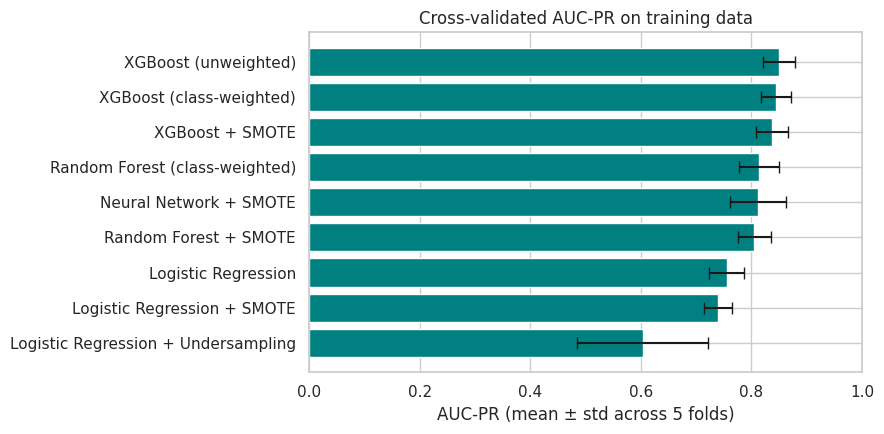

Highest mean CV AUC-PR: XGBoost (unweighted)

Best model per metric:
  AUC-PR (mean)             : XGBoost (unweighted) (0.850)
  AUC-ROC                   : Random Forest + SMOTE (0.981)
  Precision @0.5            : XGBoost (unweighted) (0.934)
  Recall @0.5               : Logistic Regression + Undersampling (0.913)
  Best F1 (any threshold)   : XGBoost (unweighted) (0.873)


In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(cv_results["Model"][::-1], cv_results["AUC-PR (mean)"][::-1],
        xerr=cv_results["AUC-PR (std)"][::-1], color="teal", capsize=4)
ax.set_xlabel("AUC-PR (mean ± std across 5 folds)")
ax.set_title("Cross-validated AUC-PR on training data")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

best_name = cv_results.loc[0, "Model"]
print("Highest mean CV AUC-PR:", best_name)

print("\nBest model per metric:")
for metric in ["AUC-PR (mean)", "AUC-ROC", "Precision @0.5", "Recall @0.5", "Best F1 (any threshold)"]:
    r = cv_results.loc[cv_results[metric].idxmax()]
    print(f"  {metric:<26}: {r['Model']} ({r[metric]:.3f})")

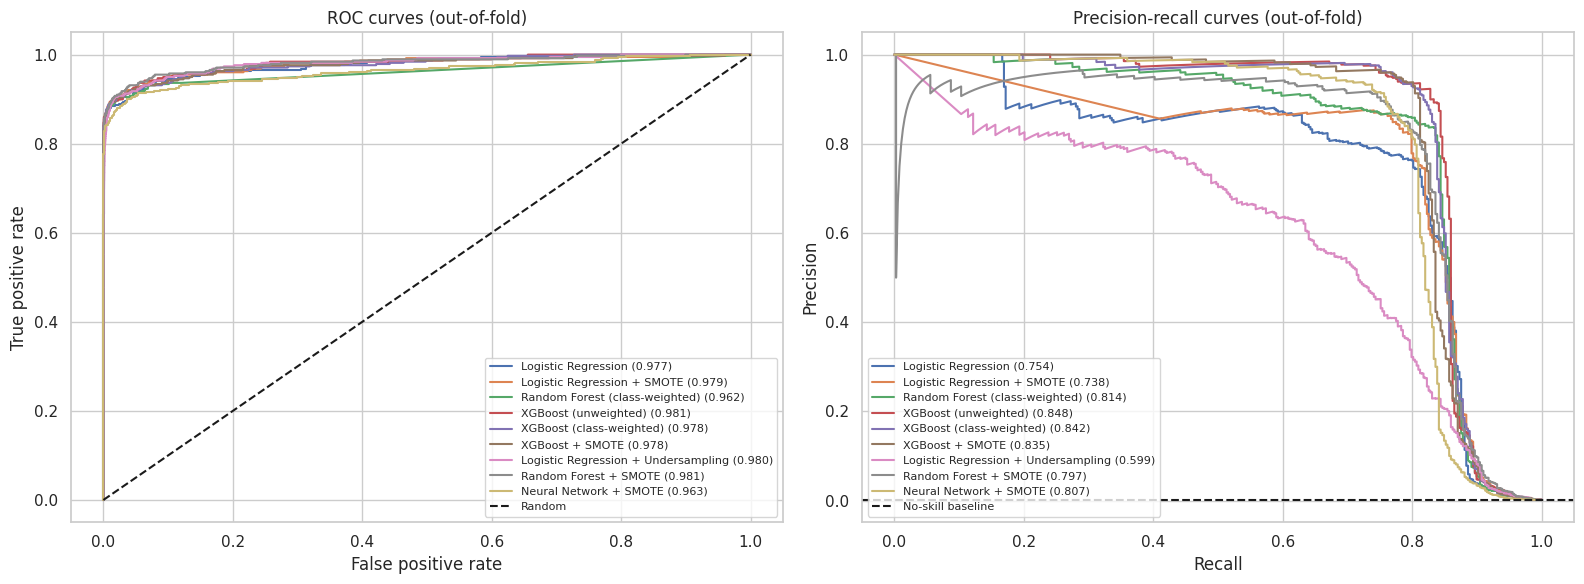

In [13]:
# ROC and precision-recall curves for every model (out-of-fold predictions on training data)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name, oof in oof_proba.items():
    fpr, tpr, _ = roc_curve(y_train, oof)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_train, oof):.3f})")
    p_, r_, _ = precision_recall_curve(y_train, oof)
    axes[1].plot(r_, p_, label=f"{name} ({average_precision_score(y_train, oof):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (out-of-fold)"); axes[0].legend(fontsize=8)
axes[1].axhline(y_train.mean(), color="k", linestyle="--", label="No-skill baseline")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (out-of-fold)"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

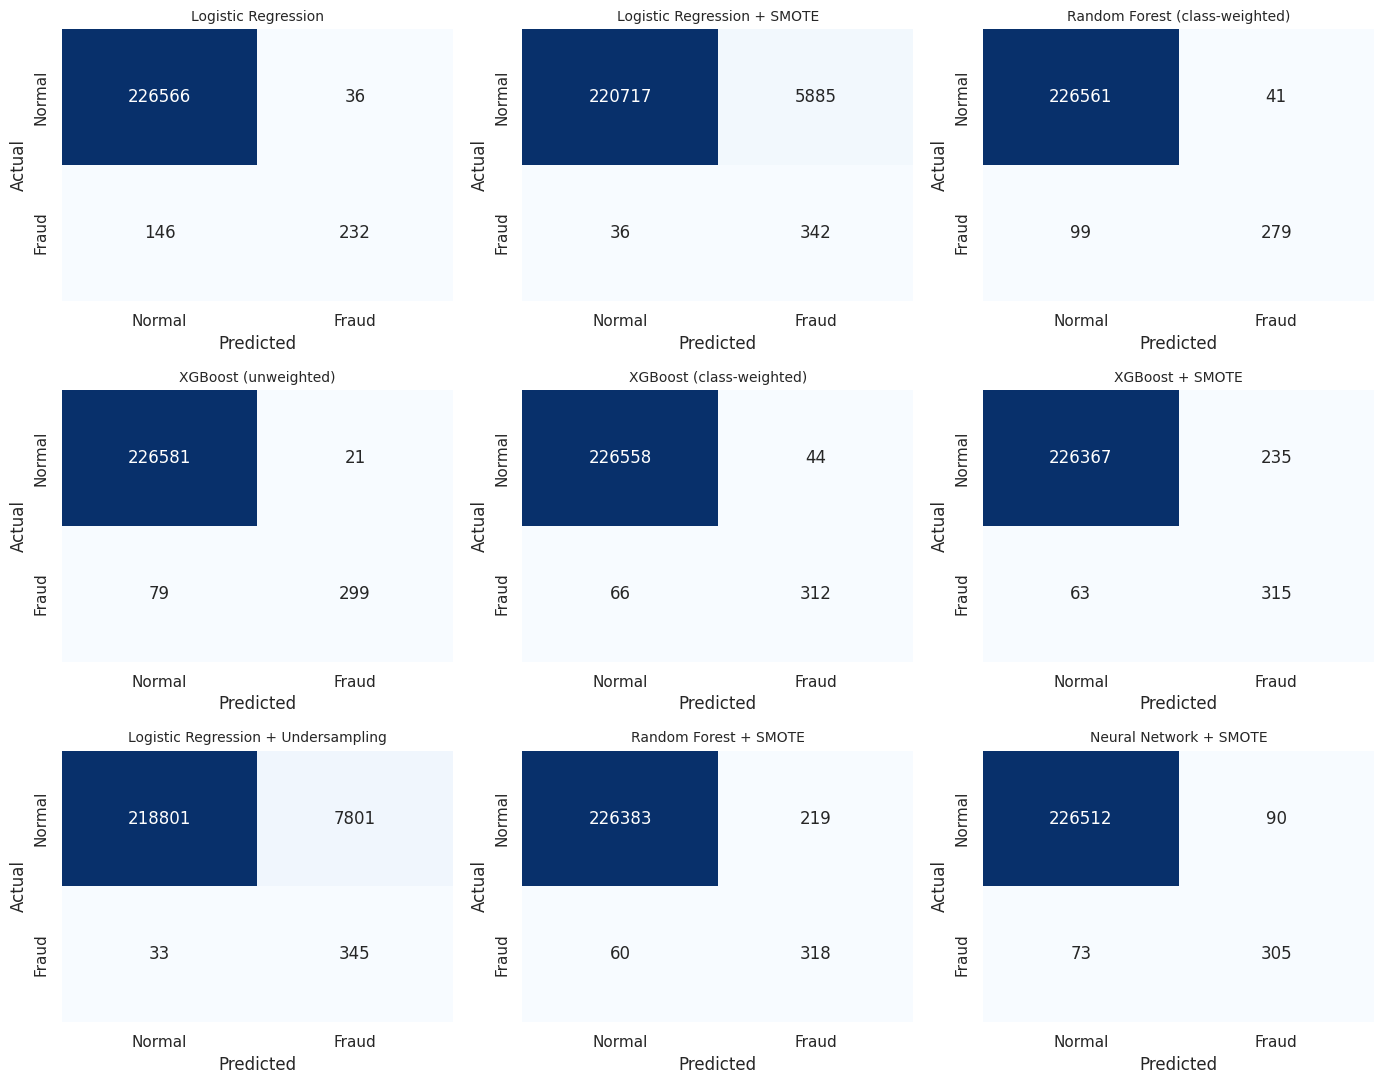

In [14]:
# Confusion matrix of every model at the default 0.5 threshold (out-of-fold, training data)
names = list(oof_proba)
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, name in zip(axes.flatten(), names):
    cm = confusion_matrix(y_train, (oof_proba[name] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

**How to read this table.** AUC-PR says how well each model *ranks* fraud above normal traffic. "Precision @0.5" and "Recall @0.5" show what happens with the default cut-off. Models trained on SMOTE-balanced data usually catch more fraud at 0.5 but flag far more normal transactions, which is a threshold effect rather than a better model. Differences smaller than the fold-to-fold standard deviation should not be treated as real.

## 6. Threshold selection

The default 0.5 cut-off is arbitrary for an imbalanced problem. The threshold for the chosen model is picked using **out-of-fold predictions on the training set** (the point on the precision-recall curve that maximizes F1), so the test set stays untouched.

Chosen model     : XGBoost (unweighted)
Chosen threshold : 0.197  (out-of-fold precision 0.923, recall 0.828, F1 0.873)


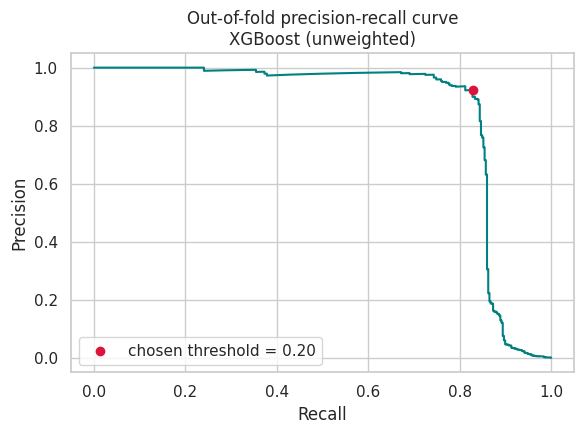

In [15]:
best_pipe = candidates[best_name]
oof_best = oof_proba[best_name]

thr, f1_at_thr, p_at_thr, r_at_thr = best_f1_threshold(y_train, oof_best)
print(f"Chosen model     : {best_name}")
print(f"Chosen threshold : {thr:.3f}  (out-of-fold precision {p_at_thr:.3f}, recall {r_at_thr:.3f}, F1 {f1_at_thr:.3f})")

prec, rec, _ = precision_recall_curve(y_train, oof_best)
plt.figure(figsize=(6, 4.5))
plt.plot(rec, prec, color="teal")
plt.scatter([r_at_thr], [p_at_thr], color="crimson", zorder=3, label=f"chosen threshold = {thr:.2f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Out-of-fold precision-recall curve\n{best_name}")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Final evaluation on the held-out test set

The selected model is trained on the full training set and evaluated on the test set **once**. A bootstrap interval shows how uncertain the number is, since the test set contains only a few dozen fraud cases.

In [16]:
final_model = clone(best_pipe).fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]

test_ap = average_precision_score(y_test, test_proba)
test_auc = roc_auc_score(y_test, test_proba)

# Bootstrap 95% interval for AUC-PR
rng = np.random.default_rng(RANDOM_STATE)
yt, pt = y_test.values, test_proba
boot = []
for _ in range(500):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() > 0:
        boot.append(average_precision_score(yt[idx], pt[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Test AUC-PR : {test_ap:.3f}   (95% bootstrap interval {lo:.3f} - {hi:.3f})")
print(f"Test AUC-ROC: {test_auc:.3f}\n")

def summarize(threshold):
    pred = (test_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return pred, {"Threshold": threshold, "Precision": tp / (tp + fp) if tp + fp else 0.0,
                  "Recall": tp / (tp + fn), "F1": f1_score(y_test, pred),
                  "TP (caught)": tp, "FN (missed)": fn, "FP (false alarms)": fp, "TN": tn}

pred_default, s_default = summarize(0.5)
pred_tuned, s_tuned = summarize(thr)
display(pd.DataFrame([s_default, s_tuned], index=["Default 0.5", "Tuned threshold"]))

Test AUC-PR : 0.831   (95% bootstrap interval 0.765 - 0.901)
Test AUC-ROC: 0.977



,Threshold,Precision,Recall,F1,TP (caught),FN (missed),FP (false alarms),TN
Default 0.5,0.5000,0.9577,0.7158,0.8193,68,27,3,56648
Tuned threshold,0.1968,0.9481,0.7684,0.8488,73,22,4,56647


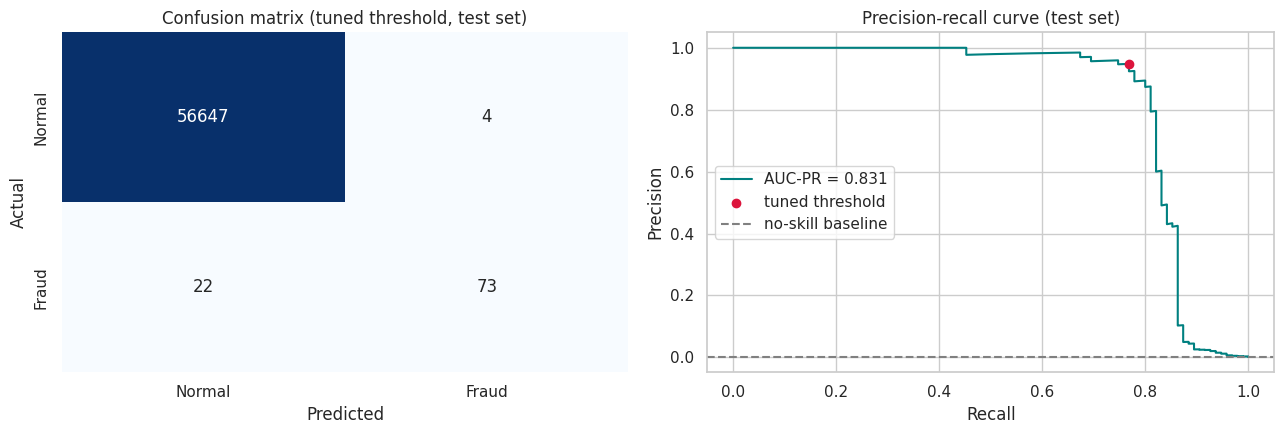

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cm = confusion_matrix(y_test, pred_tuned)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
axes[0].set_title("Confusion matrix (tuned threshold, test set)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

p, r, _ = precision_recall_curve(y_test, test_proba)
axes[1].plot(r, p, color="teal", label=f"AUC-PR = {test_ap:.3f}")
axes[1].scatter([s_tuned["Recall"]], [s_tuned["Precision"]], color="crimson", zorder=3, label="tuned threshold")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label="no-skill baseline")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Robustness check: chronological split

A random split lets the model see transactions from the same period it is tested on. In production the model only ever predicts the *future*, so the same pipeline is also trained on the first 80% of the timeline and tested on the last 20%.

In [18]:
df_sorted = df.sort_values("Time").reset_index(drop=True)
cut = int(len(df_sorted) * 0.8)
tr_t, te_t = df_sorted.iloc[:cut], df_sorted.iloc[cut:]

m_time = clone(best_pipe).fit(tr_t.drop(columns="Class"), tr_t["Class"])
p_time = m_time.predict_proba(te_t.drop(columns="Class"))[:, 1]
pred_time = (p_time >= thr).astype(int)
tn, fp, fn, tp = confusion_matrix(te_t["Class"], pred_time).ravel()

print(f"Chronological test set: {len(te_t):,} rows, {te_t['Class'].sum()} fraud")
print(f"AUC-PR   : {average_precision_score(te_t['Class'], p_time):.3f}")
print(f"Precision: {tp / (tp + fp):.3f}   Recall: {tp / (tp + fn):.3f}   (threshold {thr:.3f})")
print(f"Caught {tp}, missed {fn}, false alarms {fp}")

Chronological test set: 56,746 rows, 74 fraud
AUC-PR   : 0.787
Precision: 0.887   Recall: 0.743   (threshold 0.197)
Caught 55, missed 19, false alarms 7


### Which features matter?

Feature importance of the final model. Because `V1`-`V28` are anonymized, this says *which signals* drive predictions but not *what they mean* in business terms.

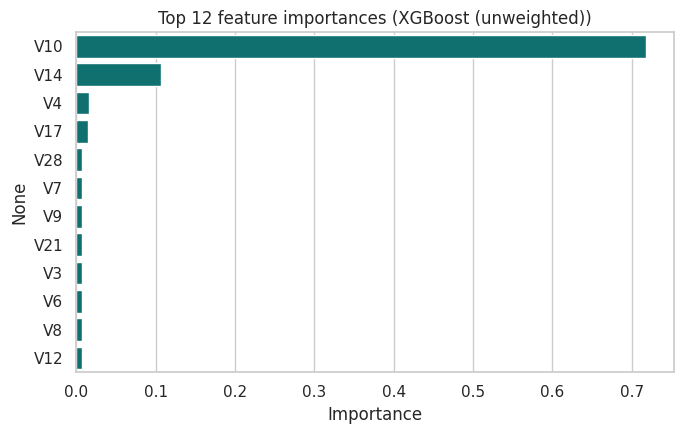

In [19]:
inner = final_model.named_steps["model"]
if hasattr(inner, "feature_importances_"):
    imp = pd.Series(inner.feature_importances_, index=FEATURES).sort_values(ascending=False).head(12)
    plt.figure(figsize=(7, 4.5))
    sns.barplot(x=imp.values, y=imp.index, color="teal", orient="h")
    plt.title(f"Top 12 feature importances ({best_name})")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    coefs = pd.Series(inner.coef_[0], index=FEATURES)
    print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12))

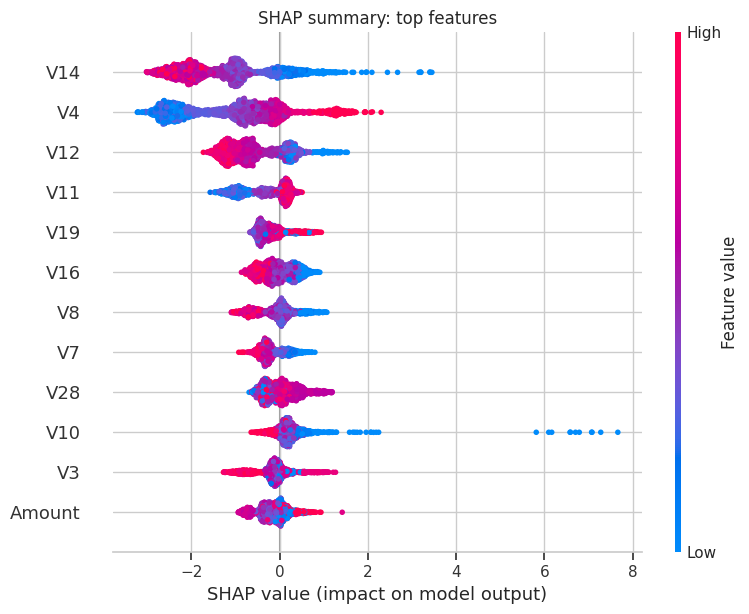

In [20]:
# SHAP: direction and size of each feature's effect on individual predictions (tree models only)
if hasattr(inner, "feature_importances_"):
    sample = X_test.sample(2000, random_state=RANDOM_STATE)
    sample_t = pd.DataFrame(final_model.named_steps["prep"].transform(sample), columns=FEATURES)
    shap_values = shap.TreeExplainer(inner).shap_values(sample_t)
    if isinstance(shap_values, list):      # older shap versions return one array per class
        shap_values = shap_values[1]
    shap.summary_plot(shap_values, sample_t, max_display=12, show=False)
    plt.title("SHAP summary: top features")
    plt.tight_layout()
    plt.show()
else:
    print("SHAP TreeExplainer is skipped because the selected model is not tree-based.")

## 8. Business impact

Using the **actual transaction amounts** and the confusion matrix on the test set.

**Assumptions (illustrative, change them to match a real business):**
- A flagged transaction is reviewed by an analyst at a fixed cost per review.
- A flagged fraud is stopped, so its full amount is saved. A missed fraud loses its full amount.
- A false alarm costs only the review (no customer-friction cost is included).
- The "no model" baseline loses every fraudulent amount.

In [21]:
amount_test = X_test["Amount"].values

def impact(pred, review_cost):
    fraud = (yt == 1)
    caught = amount_test[fraud & (pred == 1)].sum()
    missed = amount_test[fraud & (pred == 0)].sum()
    flagged = int((pred == 1).sum())
    review = flagged * review_cost
    return {"Fraud value caught": caught, "Fraud value missed": missed,
            "Transactions flagged": flagged, "Review cost": review,
            "Net benefit vs no model": caught - review}

total_fraud_value = amount_test[yt == 1].sum()
print(f"Total fraud value in test set: {total_fraud_value:,.0f}  ({int(yt.sum())} cases)\n")

REVIEW_COST = 5.0
display(pd.DataFrame({"Default 0.5": impact(pred_default, REVIEW_COST),
                      "Tuned threshold": impact(pred_tuned, REVIEW_COST)}).T
        .style.format({"Fraud value caught": "{:,.0f}", "Fraud value missed": "{:,.0f}",
                       "Transactions flagged": "{:,.0f}", "Review cost": "{:,.0f}",
                       "Net benefit vs no model": "{:,.0f}"}))

Total fraud value in test set: 14,766  (95 cases)



,Fraud value caught,Fraud value missed,Transactions flagged,Review cost,Net benefit vs no model
Default 0.5,"8,910","5,856",71,355,"8,555"
Tuned threshold,"10,961","3,805",77,385,"10,576"


In [22]:
# Sensitivity: how does the net benefit change with the cost of reviewing one transaction?
rows = []
for c in [1, 2, 5, 10, 25, 50, 100]:
    rows.append({"Review cost per flagged txn": c,
                 "Net benefit (0.5)": impact(pred_default, c)["Net benefit vs no model"],
                 "Net benefit (tuned)": impact(pred_tuned, c)["Net benefit vs no model"]})
sens = pd.DataFrame(rows)
display(sens.style.format({"Net benefit (0.5)": "{:,.0f}", "Net benefit (tuned)": "{:,.0f}"}))

share_caught = impact(pred_tuned, REVIEW_COST)["Fraud value caught"] / total_fraud_value
print(f"\nAt the tuned threshold the model catches {s_tuned['Recall']*100:.1f}% of fraud cases "
      f"and {share_caught*100:.1f}% of fraud value, flagging {s_tuned['TP (caught)'] + s_tuned['FP (false alarms)']} "
      f"of {len(y_test):,} transactions ({(s_tuned['TP (caught)'] + s_tuned['FP (false alarms)'])/len(y_test)*100:.2f}%).")

,Review cost per flagged txn,Net benefit (0.5),Net benefit (tuned)
0,1,"8,839","10,884"
1,2,"8,768","10,807"
2,5,"8,555","10,576"
3,10,"8,200","10,191"
4,25,"7,135","9,036"
5,50,"5,360","7,111"
6,100,"1,810","3,261"



At the tuned threshold the model catches 76.8% of fraud cases and 74.2% of fraud value, flagging 77 of 56,746 transactions (0.14%).


## 9. Conclusions and limitations


### Key findings

1. **Fraud is rare and mostly small.** After removing 1,081 duplicate rows, 473 of 283,726 transactions (0.167%) are fraud. The average fraud amount (about 124) is above the normal average (about 88), but the median fraud is much smaller (about 10 vs 22). The highest fraud rate is in transactions **under 1 unit (0.39%)**, and the lowest in the 10-50 band (0.06%).
2. **Fraud rate spikes in low-traffic hours.** In the relative 24h cycle, hour 2 has a 1.45% fraud rate (48 cases out of 3,308), roughly 8-9x the average. `Time` is relative to the start of the data, not the clock, and counts per hour are small, so treat this as a pattern worth investigating, not a rule.
3. **Gradient boosting is the best model family here.** The XGBoost variants reach a cross-validated AUC-PR of about 0.84-0.85, Random Forest and the neural network about 0.80-0.81, Logistic Regression about 0.75, and Logistic Regression with undersampling only 0.60 (and very unstable). The three XGBoost variants are within one fold-standard-deviation (about 0.03) of each other, so the differences between them are not meaningful.
4. **Resampling did not help.** SMOTE pushed recall up at the 0.5 cut-off but collapsed precision (Logistic Regression + SMOTE: 5% precision; XGBoost + SMOTE: 57% vs 93% for plain XGBoost; Random Forest + SMOTE: 59% vs 87% class-weighted) without improving AUC-PR. Random undersampling was the worst option (4% precision). The simple, unweighted XGBoost ranked first, so no resampling was needed once the threshold was tuned.
5. **Held-out test performance:** AUC-PR 0.83 (95% bootstrap interval 0.77-0.90). At the tuned threshold (0.197) the model catches **73 of 95 frauds (77% recall) with 95% precision**, flagging only 77 of 56,746 transactions (0.14%): 22 frauds missed and 4 false alarms.
6. **What drives predictions:** `V14` and `V4` are the strongest signals, followed by `V12`, `V11` and `V10`. SHAP shows that low `V14`, low `V12` and high `V4` push a transaction toward "fraud". Because the features are anonymized, this shows *which* signals matter but not what they mean in business terms.
7. **Business view (illustrative assumptions):** the tuned threshold stops about 74% of fraud value and beats the default 0.5 cut-off at every review cost tested, with a positive net benefit even at 100 per review.

### Limitations

- **Small number of fraud cases:** only 95 frauds in the test set, so every fraud-related metric is uncertain (see the bootstrap interval).
- **Random vs chronological split:** with a chronological split the same pipeline gets AUC-PR 0.79 and 74% recall, a more realistic expectation for future data. The data covers only two days, so seasonality and fraud-pattern drift cannot be assessed.
- **Anonymized features:** `V1`-`V28` cannot be explained to a business stakeholder.
- **Business numbers are assumptions:** review cost, "flagged fraud is fully prevented" and "no customer-friction cost" are placeholders, and the amount currency is not stated in the data.
- **Not included:** SMOTEENN was left out because it takes many minutes per cross-validation fold and gave no gain over plain SMOTE in earlier tests. A hand-weighted composite score was also left out; models are compared on cross-validated AUC-PR with a threshold chosen on training data, which is easier to defend.
- **Possible next steps:** probability calibration, cost-sensitive threshold selection, hyperparameter tuning, and drift monitoring.


In [23]:
print("=== RESULTS SUMMARY ===")
print(f"Rows after cleaning       : {len(df):,} ({df['Class'].sum()} fraud, {df['Class'].mean()*100:.3f}%)")
print(f"Selected model (CV)       : {best_name}")
print(f"CV AUC-PR                 : {cv_results.loc[0, 'AUC-PR (mean)']:.3f} ± {cv_results.loc[0, 'AUC-PR (std)']:.3f}")
print(f"Test AUC-PR               : {test_ap:.3f} (95% CI {lo:.3f}-{hi:.3f})")
print(f"Test precision / recall   : {s_tuned['Precision']:.3f} / {s_tuned['Recall']:.3f} at threshold {thr:.3f}")
print(f"Caught / missed / false+  : {s_tuned['TP (caught)']} / {s_tuned['FN (missed)']} / {s_tuned['FP (false alarms)']}")

=== RESULTS SUMMARY ===
Rows after cleaning       : 283,726 (473 fraud, 0.167%)
Selected model (CV)       : XGBoost (unweighted)
CV AUC-PR                 : 0.850 ± 0.028
Test AUC-PR               : 0.831 (95% CI 0.765-0.901)
Test precision / recall   : 0.948 / 0.768 at threshold 0.197
Caught / missed / false+  : 73 / 22 / 4
